In [1]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

sns.set_theme(style='whitegrid')
np.random.seed(42)
print("comlpleted")

comlpleted


In [2]:
# 2.1 Load the raw nutrition dataset
df = pd.read_csv('../datasets/nutrition.csv')

print('Dataset Shape:', df.shape)
print('\nData Types:')
print(df.dtypes.value_counts())
print('\nMissing Values:')
print(df.isnull().sum())
print('\nDuplicate Rows:', df.duplicated().sum())
print('\nOriginal Target Distribution:')
print(df['category'].value_counts())

Dataset Shape: (1818, 24)

Data Types:
float64    22
str         2
Name: count, dtype: int64

Missing Values:
food_name          0
category           0
calories           0
protein_g          0
carbohydrates_g    0
fat_g              0
fiber_g            0
sugars_g           0
calcium_mg         0
iron_mg            0
sodium_mg          0
potassium_mg       0
magnesium_mg       0
phosphorus_mg      0
zinc_mg            0
vitamin_a_iu       0
vitamin_c_mg       0
vitamin_b1_mg      0
vitamin_b2_mg      0
vitamin_b3_mg      0
vitamin_b5_mg      0
vitamin_b6_mg      0
vitamin_e_mg       0
folate_mcg         0
dtype: int64

Duplicate Rows: 0

Original Target Distribution:
category
Indian Food             1014
Vegetable                160
Condiment                115
Fruit                     82
General                   66
Beverage                  52
Grain                     49
Meal/Processed            28
Protein/Meat              27
Dairy                     26
Dessert                 

Shape after duplicate removal: (1818, 25)

Classification Target Distribution:
category_group
Indian Food       1014
Other              199
Vegetable          160
Condiment          115
Fruit               82
General             66
Beverage            52
Grain               49
Meal/Processed      28
Protein/Meat        27
Dairy               26
Name: count, dtype: int64


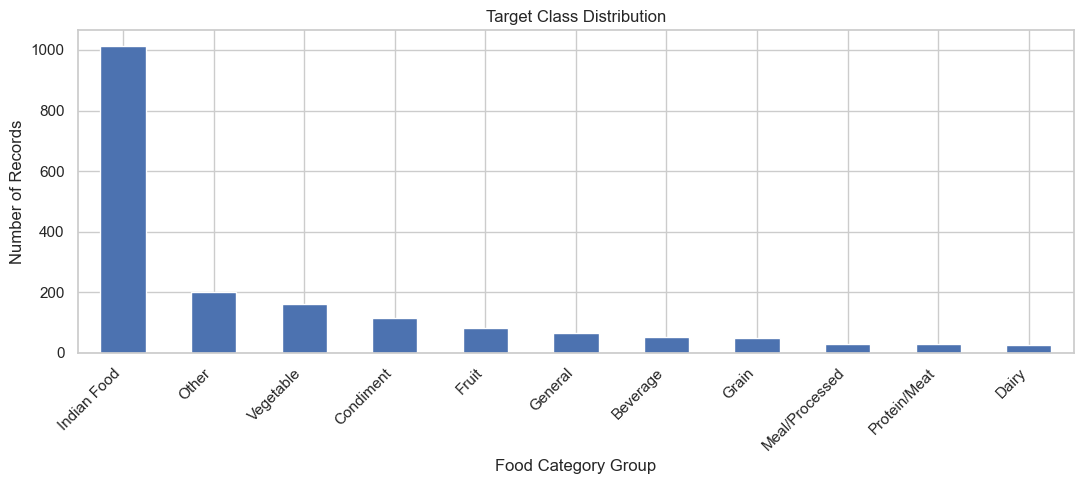

In [3]:
# 2.2 Remove duplicates and create the classification target
df = df.drop_duplicates().copy()

top_categories = df['category'].value_counts().head(10).index
df['category_group'] = df['category'].where(df['category'].isin(top_categories), 'Other')

print('Shape after duplicate removal:', df.shape)
print('\nClassification Target Distribution:')
print(df['category_group'].value_counts())

plt.figure(figsize=(11,5))
df['category_group'].value_counts().plot(kind='bar')
plt.xticks(rotation=45, ha='right')
plt.title('Target Class Distribution')
plt.xlabel('Food Category Group')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

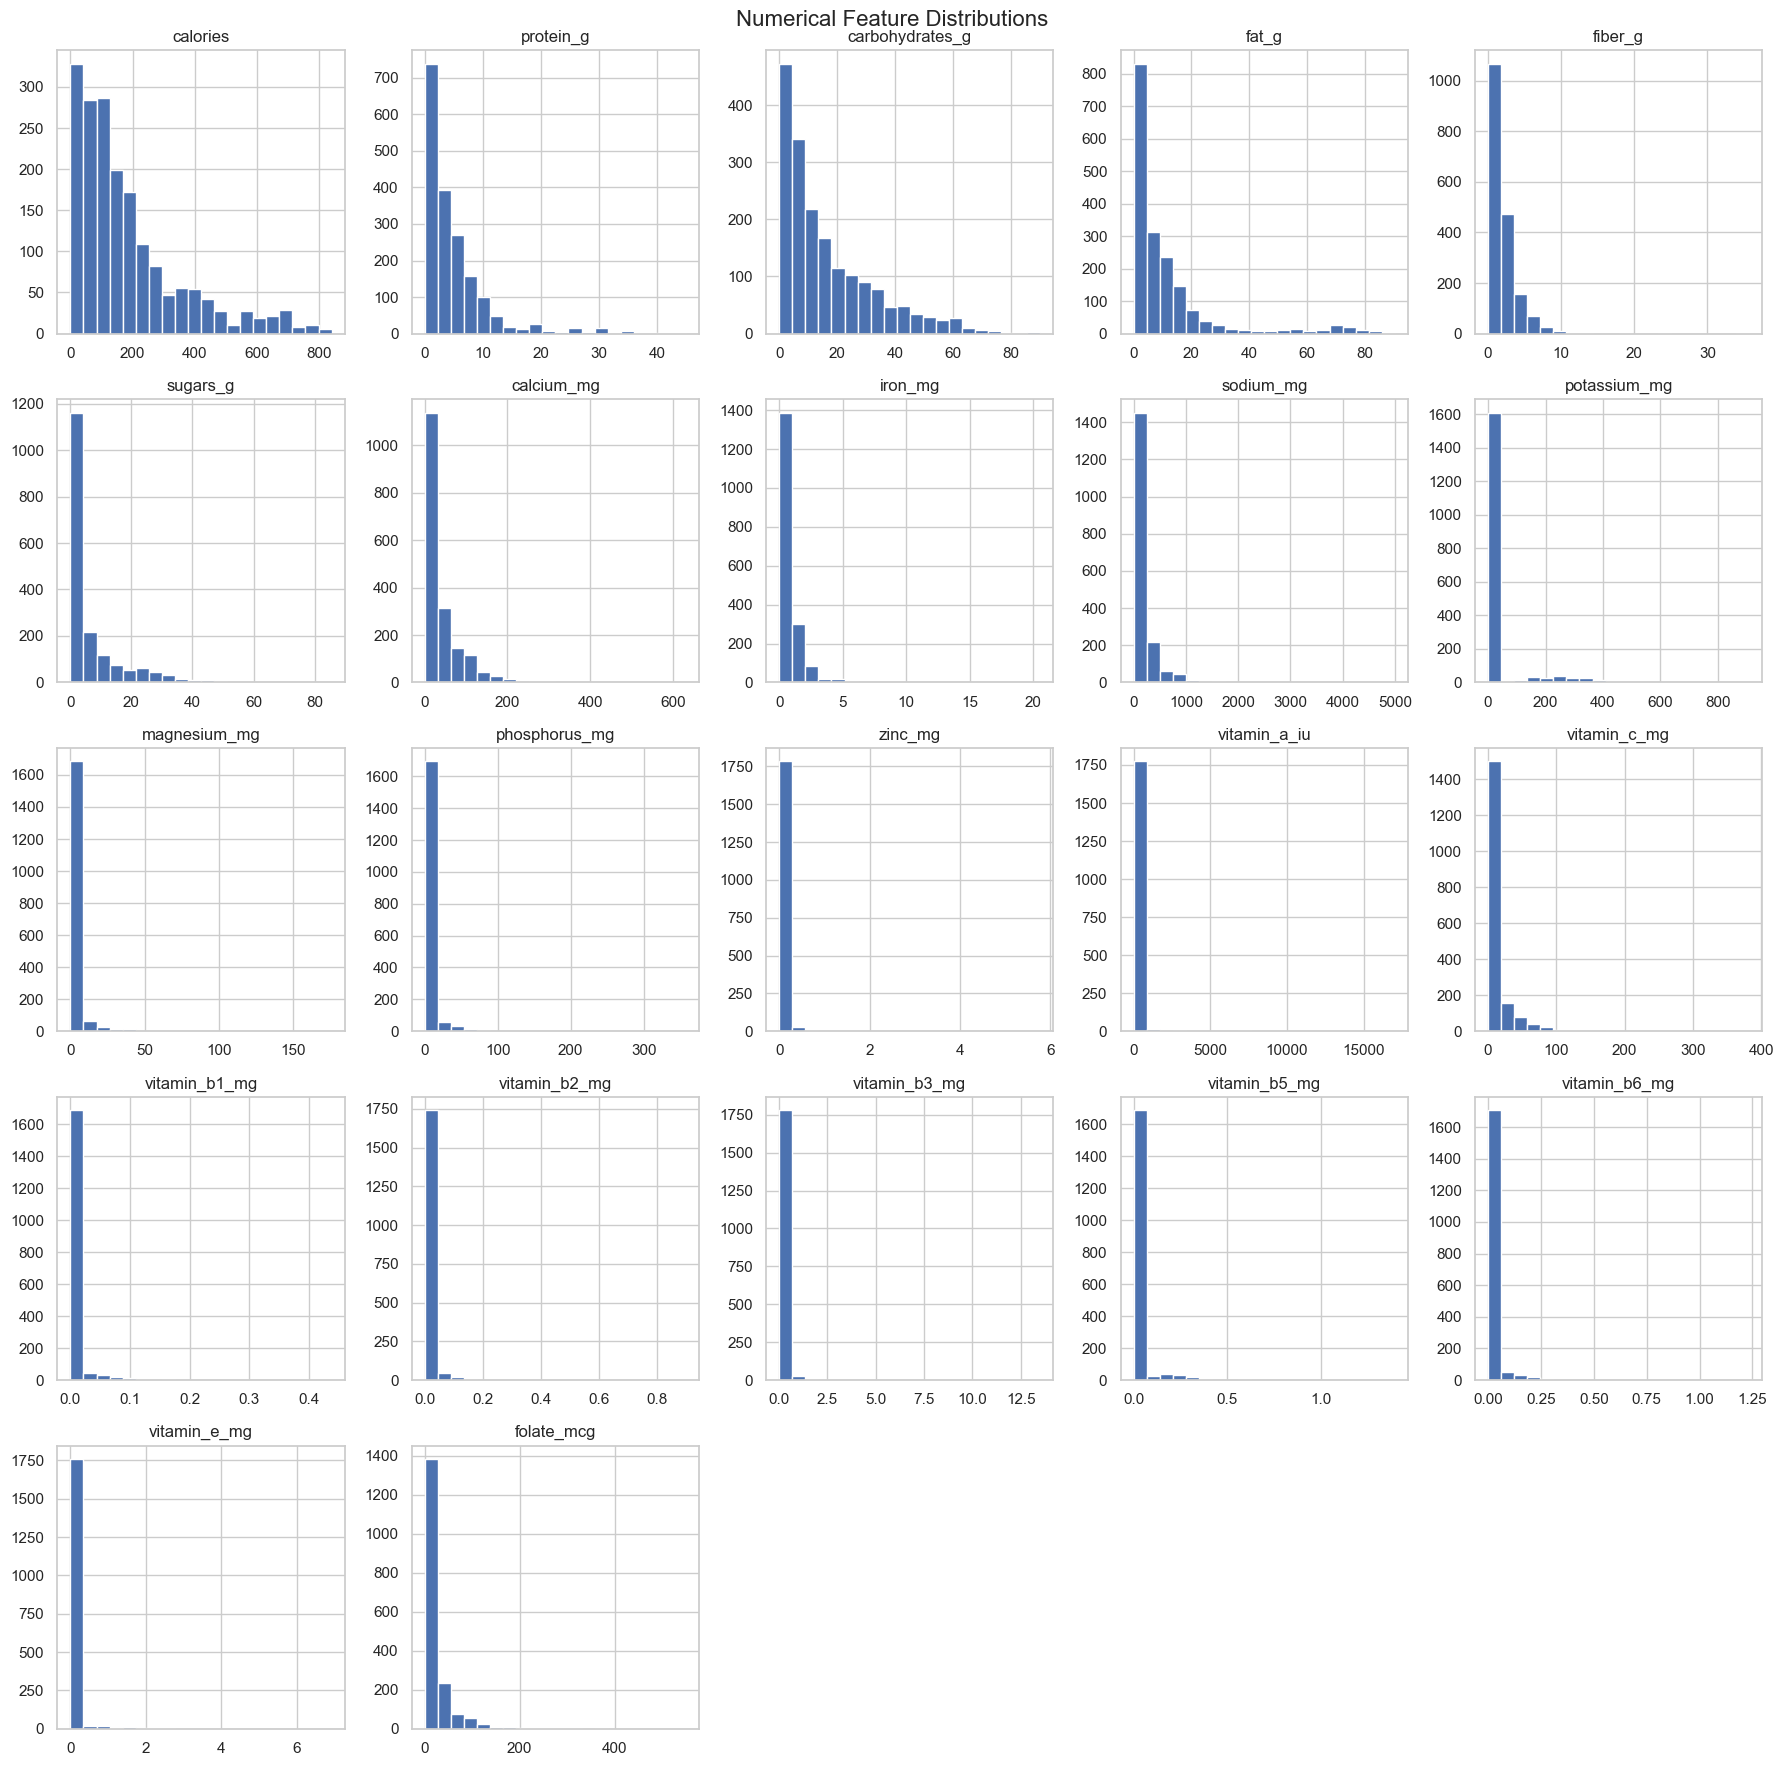

In [4]:
# 2.3 Numerical feature distributions
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(figsize=(18,18), bins=20)
plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

In [5]:
# 2.4 Categorical distributions
print('Food Category Counts:')
print(df['category'].value_counts())

print('\nFood Name Count:', df['food_name'].nunique())

Food Category Counts:
category
Indian Food             1014
Vegetable                160
Condiment                115
Fruit                     82
General                   66
Beverage                  52
Grain                     49
Meal/Processed            28
Protein/Meat              27
Dairy                     26
Dessert                   26
Meal/Meat                 19
Snack/Processed           15
Meal/Pasta                14
Nut                       13
Meal/Vegetarian           10
Legume                     9
Meal/Vegetable             8
Protein/Fish               8
Grain/Processed            7
Meal/Seafood               6
Protein/Vegetarian         6
Condiment/Dairy            5
Meal/Grain                 5
Protein/Seafood            5
Protein                    4
Meal/Protein               4
Meal/Soup                  4
Vegetable/Processed        3
Beverage/Dairy-Alt         3
Meal/Fish                  3
Meal/Legume                3
Beverage/Dairy             2
Meal/Rice   

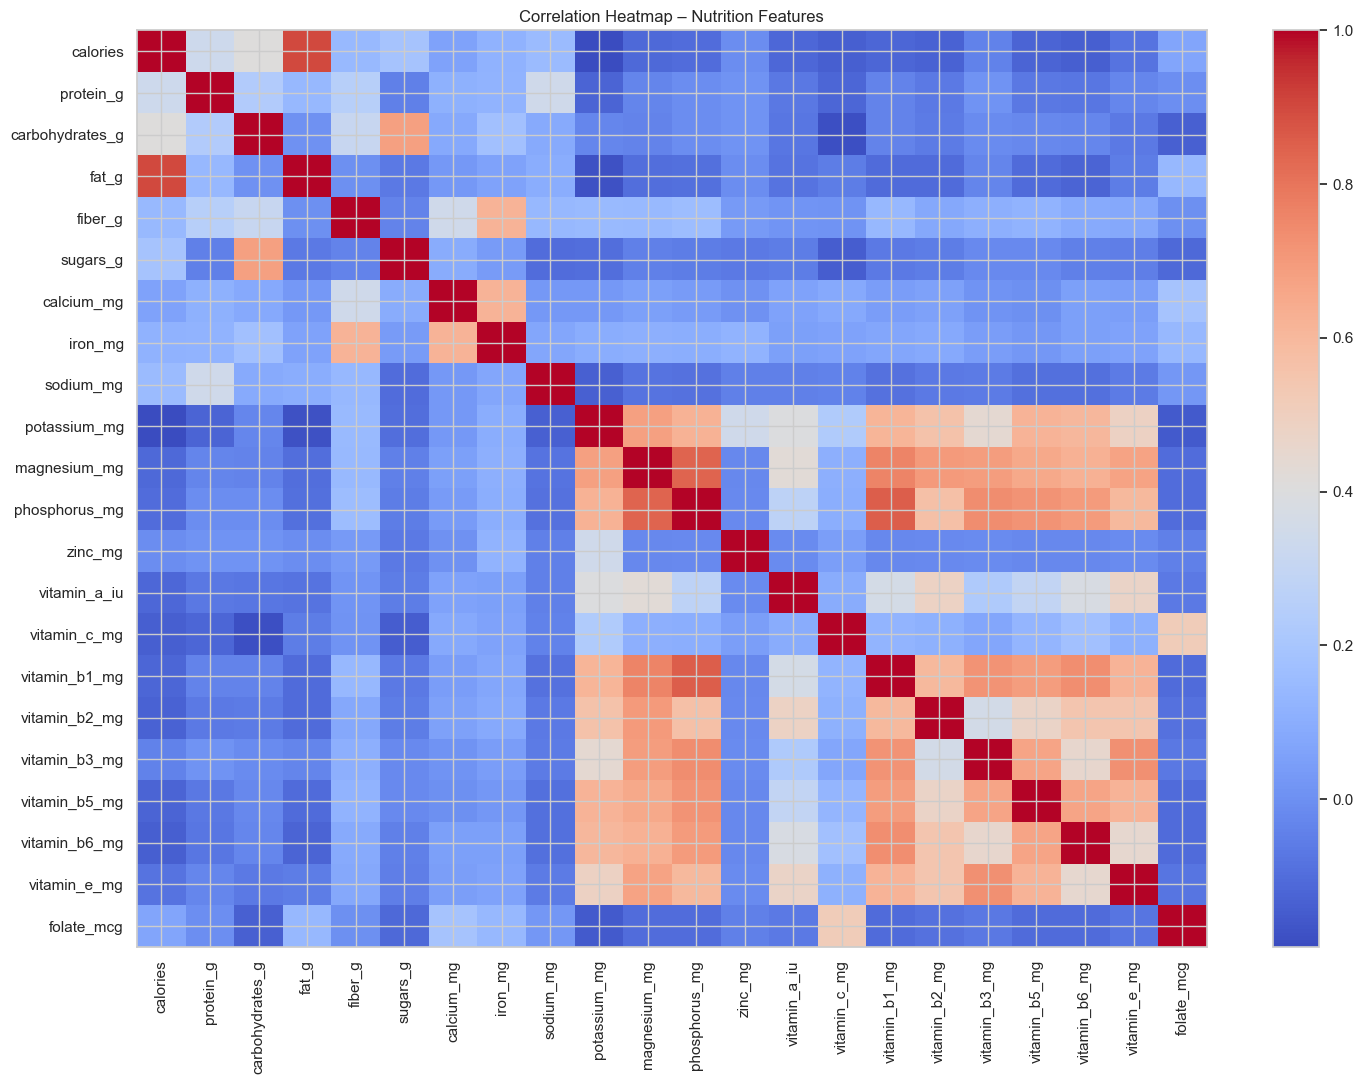

In [6]:
# 2.5 Correlation heatmap
plt.figure(figsize=(15,11))
corr = df[numeric_cols].corr()
plt.imshow(corr, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation Heatmap – Nutrition Features')
plt.tight_layout()
plt.show()

**Observation:** The heatmap shows relationships among calories, macronutrients and micronutrients. Strong correlations can indicate redundant information, while weaker relationships may provide additional classification information.

<Figure size 1000x500 with 0 Axes>

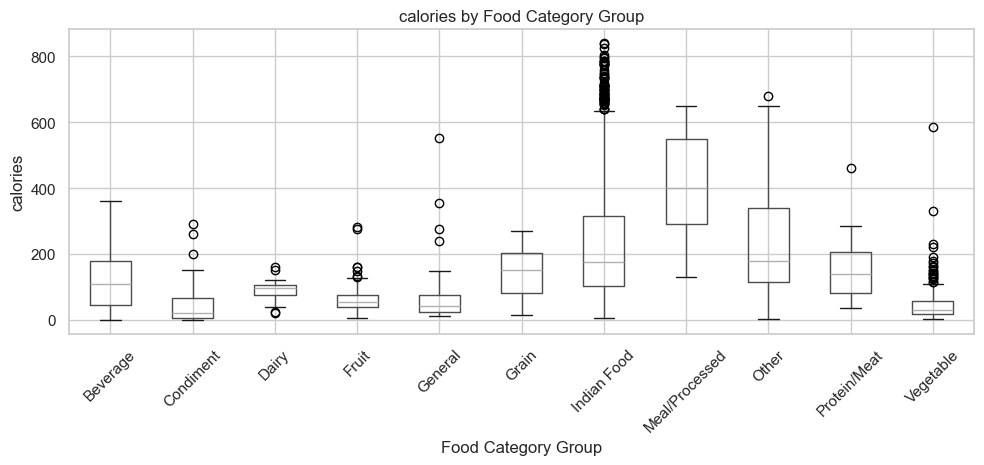

<Figure size 1000x500 with 0 Axes>

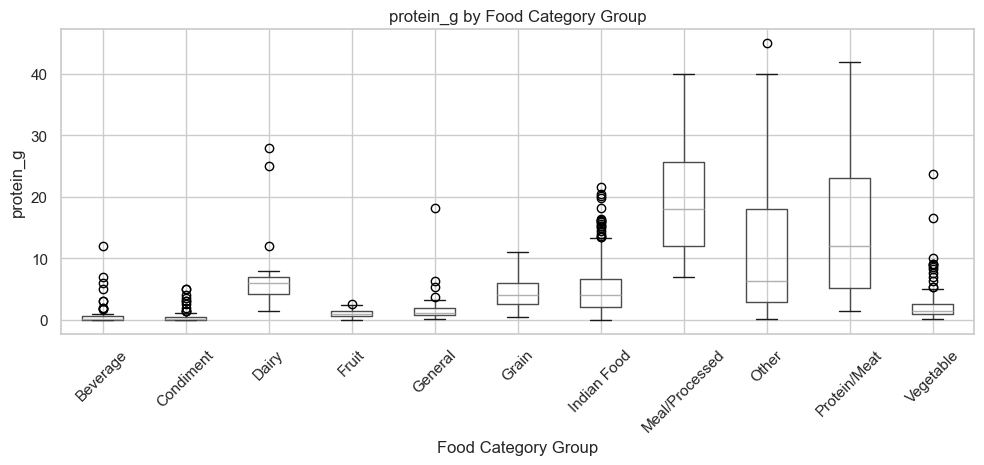

<Figure size 1000x500 with 0 Axes>

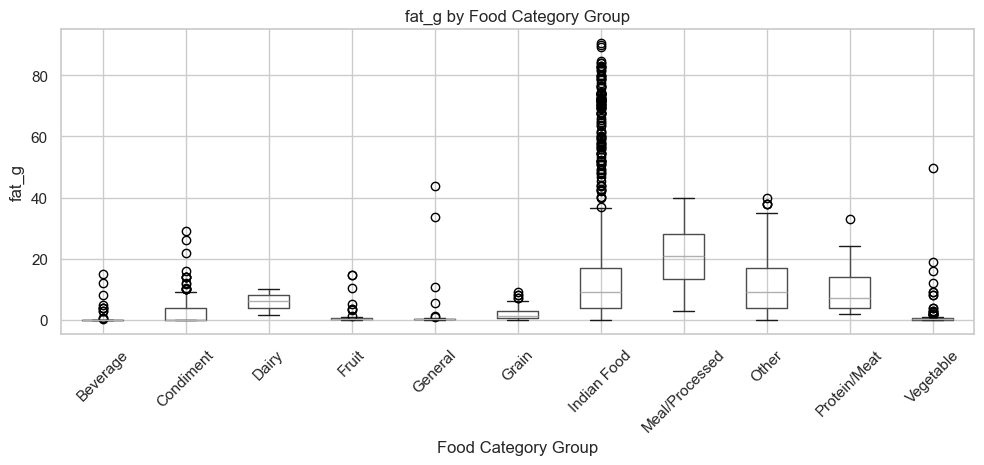

In [7]:
# 2.6 Feature-target relationship plots
for col in ['calories', 'protein_g', 'fat_g']:
    plt.figure(figsize=(10,5))
    df.boxplot(column=col, by='category_group', rot=45, figsize=(10,5))
    plt.title(f'{col} by Food Category Group')
    plt.suptitle('')
    plt.xlabel('Food Category Group')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [8]:
# 3.1 Missing values and duplicates
print('Total Missing Values:', df.isnull().sum().sum())
print('Duplicate Rows:', df.duplicated().sum())

# Outlier count using the IQR rule
outlier_counts = {}
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outlier_counts[col] = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()

print('\nOutlier Counts:')
print(pd.Series(outlier_counts).sort_values(ascending=False))

Total Missing Values: 0
Duplicate Rows: 0

Outlier Counts:
vitamin_c_mg       230
sugars_g           226
potassium_mg       210
folate_mcg         169
sodium_mg          156
fat_g              152
phosphorus_mg      145
vitamin_b3_mg      144
vitamin_b2_mg      144
magnesium_mg       143
vitamin_b1_mg      143
vitamin_b6_mg      143
vitamin_b5_mg      139
vitamin_a_iu       128
vitamin_e_mg       124
calories           124
protein_g          112
calcium_mg         106
fiber_g            102
iron_mg             75
zinc_mg             66
carbohydrates_g     59
dtype: int64


In [9]:
# 4.1 Feature engineering
df['total_macros_g'] = (
    df['protein_g'] + df['carbohydrates_g'] + df['fat_g']
)

df['fat_carb_ratio'] = df['fat_g'] / (df['carbohydrates_g'] + 1)
df['protein_carb_ratio'] = df['protein_g'] / (df['carbohydrates_g'] + 1)

print(df[['total_macros_g', 'fat_carb_ratio', 'protein_carb_ratio']].describe().T)

                     count       mean        std  min        25%        50%  \
total_macros_g      1818.0  32.834664  25.853614  0.0  12.917500  25.675000   
fat_carb_ratio      1818.0   1.598550   3.608075  0.0   0.051037   0.344461   
protein_carb_ratio  1818.0   0.796023   2.743388  0.0   0.109115   0.210035   

                          75%         max  
total_macros_g      47.737500  128.000000  
fat_carb_ratio       1.014579   37.388626  
protein_carb_ratio   0.441644   42.000000  


In [10]:
# 4.2 Prepare features and target
X = df.drop(columns=['category', 'category_group', 'food_name']).select_dtypes(include=np.number)
y = df['category_group']

print('Feature Matrix Shape:', X.shape)
print('Target Shape:', y.shape)

Feature Matrix Shape: (1818, 25)
Target Shape: (1818,)


In [11]:
# 4.3 Stratified 80:20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 1454
Testing samples: 364


In [12]:
# 4.4 Missing values and outlier treatment using training data only
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

X_train = X_train.clip(lower=lower, upper=upper, axis=1)
X_test = X_test.clip(lower=lower, upper=upper, axis=1)

print('Training missing values:', X_train.isnull().sum().sum())
print('Testing missing values:', X_test.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [13]:
# 4.5 Standard scaling fitted only on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled training shape:', X_train_scaled.shape)
print('Scaled testing shape:', X_test_scaled.shape)

Scaled training shape: (1454, 25)
Scaled testing shape: (364, 25)


In [14]:
# Classification Models 1–2

# 1. Logistic Regression
log_model = LogisticRegression(max_iter=2000, random_state=42)
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)

log_accuracy = accuracy_score(y_test, log_pred)
log_f1 = f1_score(y_test, log_pred, average='weighted')

print('1. Logistic Regression')
print(f'Accuracy   : {log_accuracy:.4f}')
print(f'Weighted F1: {log_f1:.4f}')

# 2. K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred, average='weighted')

print('\n2. K-Nearest Neighbors')
print(f'Accuracy   : {knn_accuracy:.4f}')
print(f'Weighted F1: {knn_f1:.4f}')


1. Logistic Regression
Accuracy   : 0.8516
Weighted F1: 0.8486

2. K-Nearest Neighbors
Accuracy   : 0.8324
Weighted F1: 0.8267


In [15]:
# Classification Models 3–4

# 3. Gaussian Naive Bayes
gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)
gnb_pred = gnb_model.predict(X_test_scaled)

gnb_accuracy = accuracy_score(y_test, gnb_pred)
gnb_f1 = f1_score(y_test, gnb_pred, average='weighted')

print('3. Gaussian Naive Bayes')
print(f'Accuracy   : {gnb_accuracy:.4f}')
print(f'Weighted F1: {gnb_f1:.4f}')

# 4. Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=6, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred, average='weighted')

print('\n4. Decision Tree Classifier')
print(f'Accuracy   : {dt_accuracy:.4f}')
print(f'Weighted F1: {dt_f1:.4f}')


3. Gaussian Naive Bayes
Accuracy   : 0.8269
Weighted F1: 0.8255

4. Decision Tree Classifier
Accuracy   : 0.8791
Weighted F1: 0.8681


In [16]:
# Classification Model 5

# 5. Support Vector Classifier
svc_model = SVC(C=1.0, kernel='rbf', random_state=42)
svc_model.fit(X_train_scaled, y_train)
svc_pred = svc_model.predict(X_test_scaled)

svc_accuracy = accuracy_score(y_test, svc_pred)
svc_f1 = f1_score(y_test, svc_pred, average='weighted')

print('5. Support Vector Classifier')
print(f'Accuracy   : {svc_accuracy:.4f}')
print(f'Weighted F1: {svc_f1:.4f}')


5. Support Vector Classifier
Accuracy   : 0.8242
Weighted F1: 0.8185


Classification Model Comparison:


,Algorithm,Accuracy,Weighted F1
0,1. Logistic Regression,0.8516,0.8486
1,2. KNN,0.8324,0.8267
2,3. Gaussian Naive Bayes,0.8269,0.8255
3,4. Decision Tree,0.8791,0.8681
4,5. SVC,0.8242,0.8185


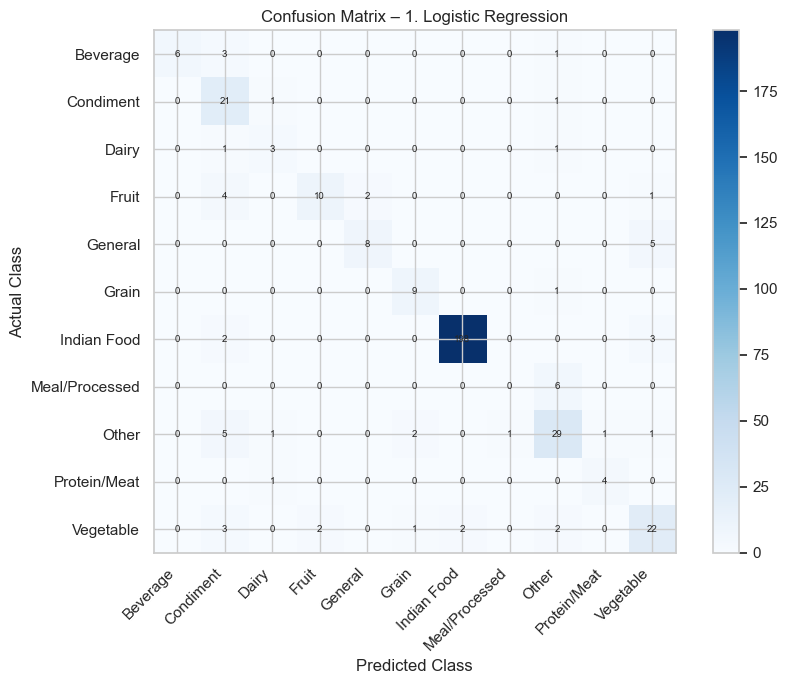

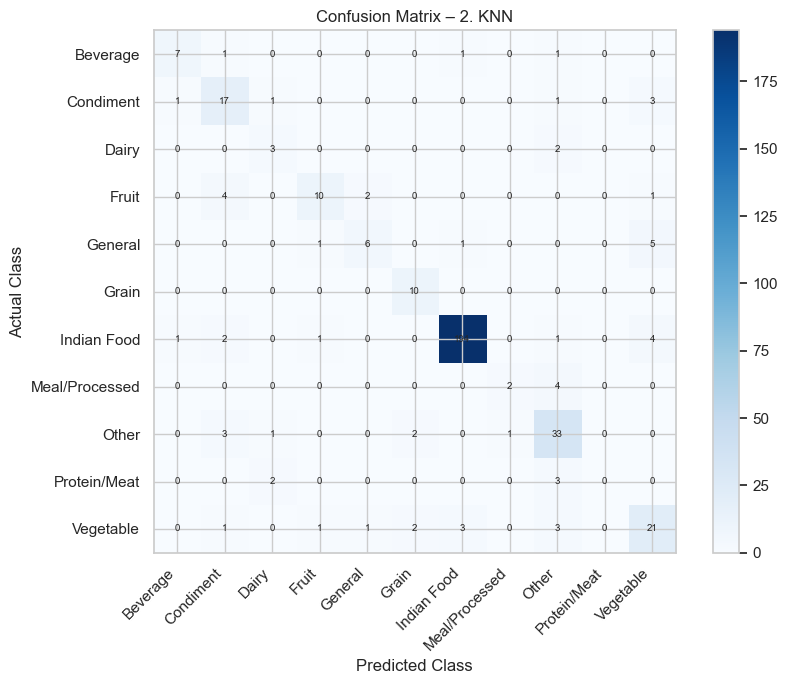

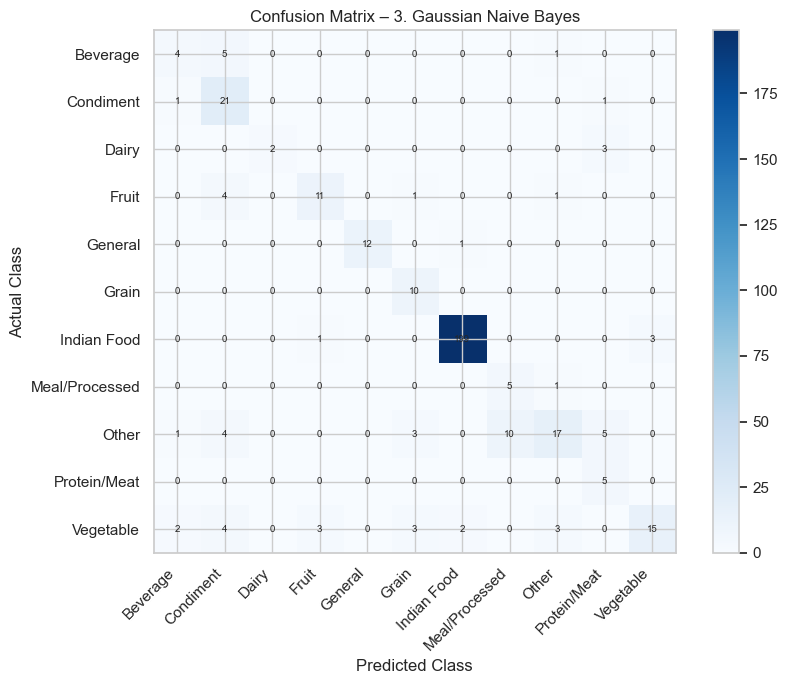

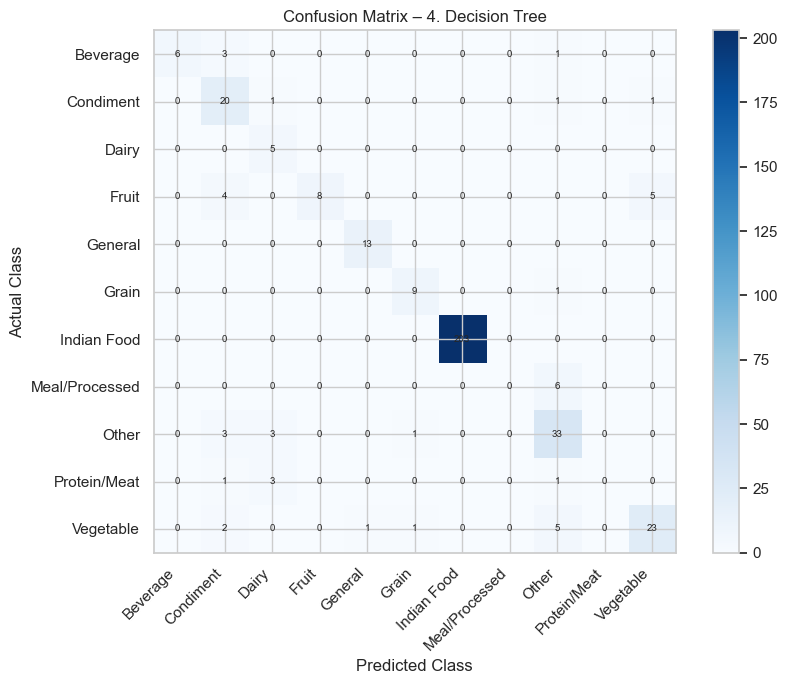

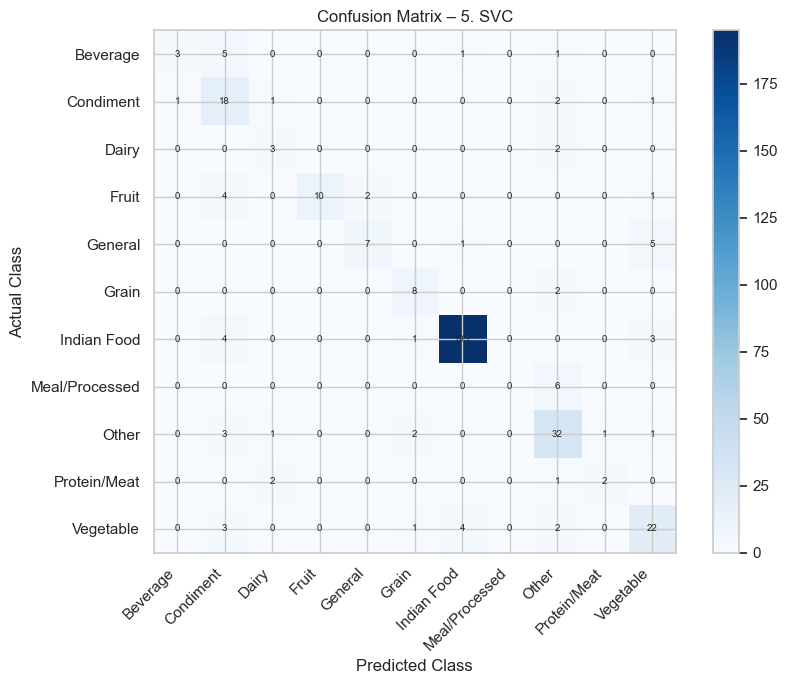

Sorted Classification Comparison:


,Algorithm,Accuracy,Weighted F1
0,4. Decision Tree,0.8791,0.8681
1,1. Logistic Regression,0.8516,0.8486
2,2. KNN,0.8324,0.8267
3,3. Gaussian Naive Bayes,0.8269,0.8255
4,5. SVC,0.8242,0.8185


In [17]:
# Final Classification Evaluation
predictions = {
    '1. Logistic Regression': log_pred,
    '2. KNN': knn_pred,
    '3. Gaussian Naive Bayes': gnb_pred,
    '4. Decision Tree': dt_pred,
    '5. SVC': svc_pred
}

comparison = []

for name, pred in predictions.items():
    accuracy = accuracy_score(y_test, pred)
    weighted_f1 = f1_score(y_test, pred, average='weighted')

    comparison.append({
        'Algorithm': name,
        'Accuracy': round(accuracy, 4),
        'Weighted F1': round(weighted_f1, 4)
    })

comparison_table = pd.DataFrame(comparison)

print('Classification Model Comparison:')
display(comparison_table)

# Confusion matrices for all five classifiers
class_labels = sorted(y_test.unique())

for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=class_labels)

    plt.figure(figsize=(9, 7))
    plt.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.colorbar()
    plt.xticks(
        range(len(class_labels)),
        class_labels,
        rotation=45,
        ha='right'
    )
    plt.yticks(range(len(class_labels)), class_labels)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, cm[i, j],
                ha='center',
                va='center',
                fontsize=7
            )

    plt.title(f'Confusion Matrix – {name}')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.tight_layout()
    plt.show()

# Sorted comparison for interpretation
classification_comparison = comparison_table.sort_values(
    'Weighted F1',
    ascending=False
).reset_index(drop=True)

print('Sorted Classification Comparison:')
display(classification_comparison)


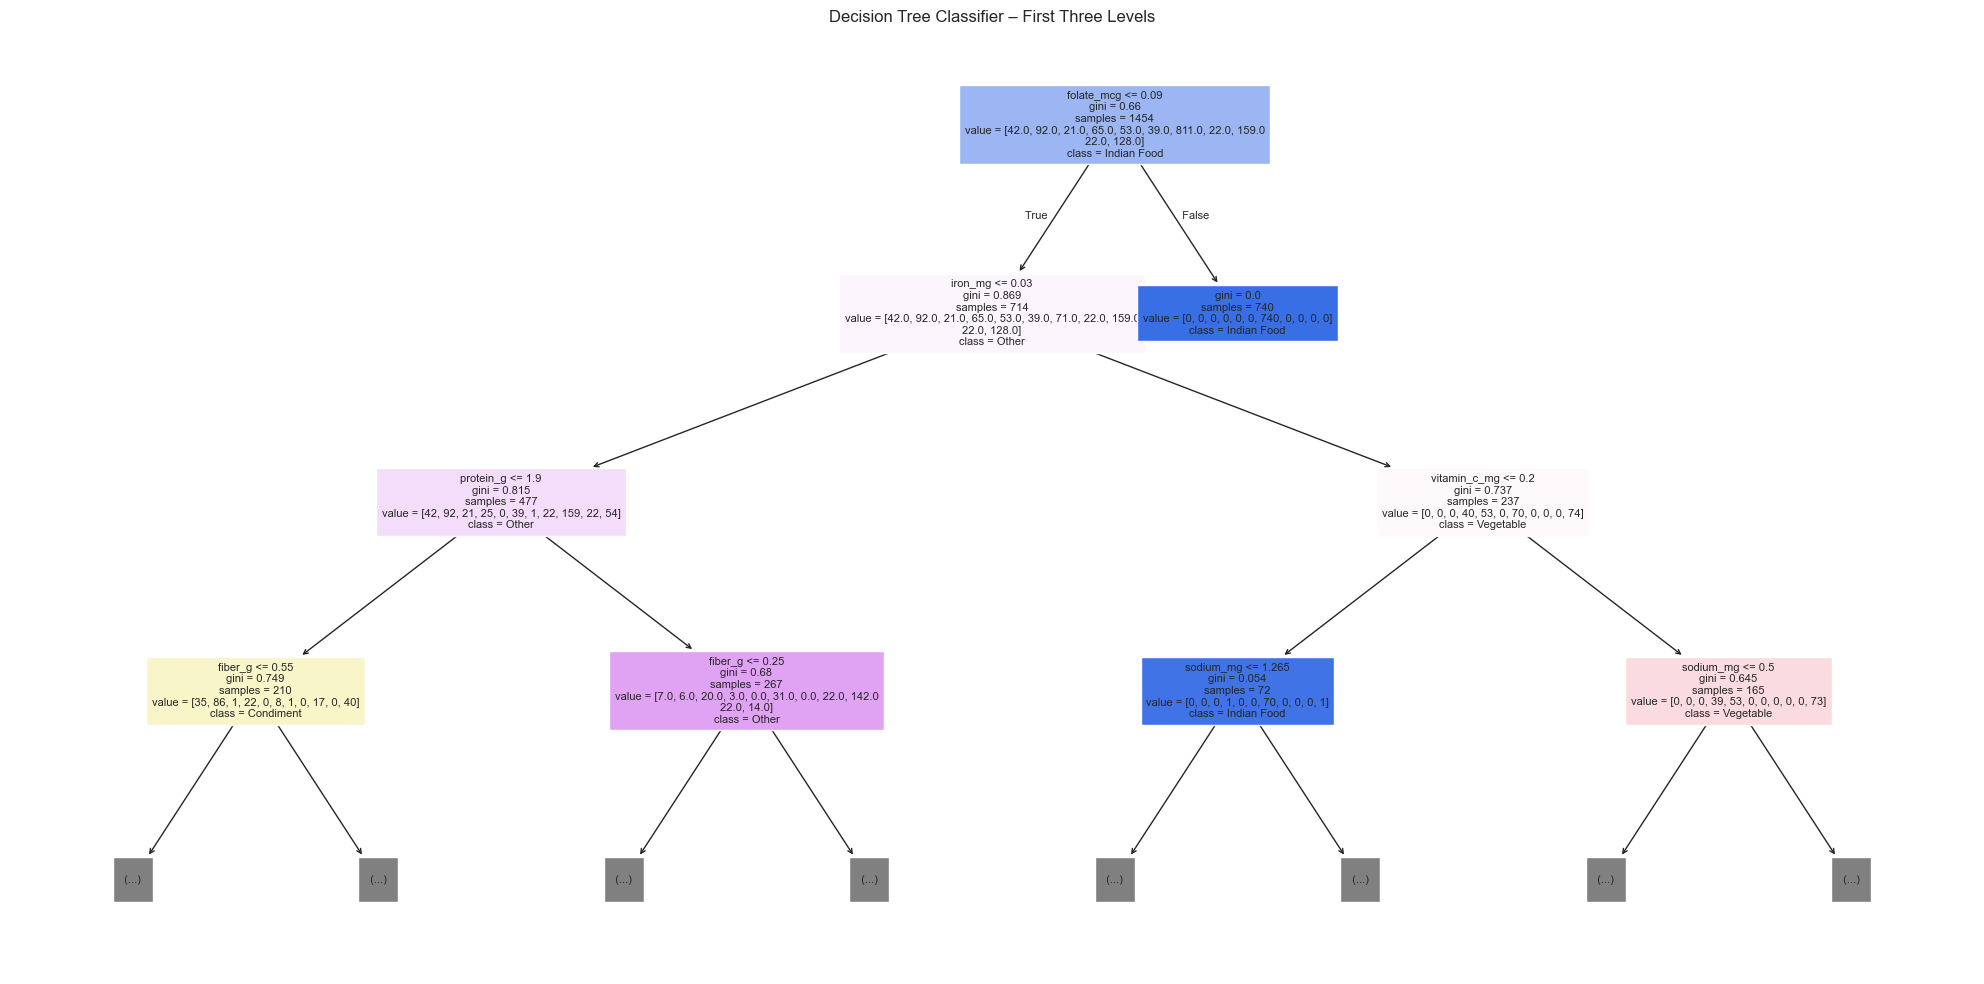

In [18]:
# Visualise the required Decision Tree model
plt.figure(figsize=(20,10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=sorted(y.unique()),
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title('Decision Tree Classifier – First Three Levels')
plt.tight_layout()
plt.show()

# Review 2 — Part B: Additional Classification Models

This section follows the original Part A cells above. Part A has been preserved; the cells below contain the new Part B classification workflow.

# Nutrition Dataset — Classification Review 2 (Part B)

**Purpose:** This is a **standalone Part B notebook** built by following the workflow and conventions of the original Nutrition Classification Part A notebook. It does **not** repeat or replace Part A.

Part B classifiers:
1. Random Forest
2. AdaBoost
3. Gradient Boosting
4. Bagging Classifier
5. MLP (Multi-Layer Perceptron) Classifier

Each model is trained in its **own cell** and evaluated with accuracy, weighted precision, weighted recall, weighted F1-score, a classification report, and a confusion matrix. The same target definition, engineered features, stratified split, imputation/outlier treatment, and scaling approach are used to keep results comparable with Part A.

## 1. Import libraries

In [19]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)

RANDOM_STATE = 42

## 2. Load the same Nutrition dataset

The notebook looks for `nutrition.csv` in common project locations. If your dataset is elsewhere, update `DATA_PATH` in the next cell.

In [20]:
possible_paths = [
    "../datasets/nutrition.csv",
    "datasets/nutrition.csv",
    "../nutrition.csv",
    "nutrition.csv",
    "/mnt/data/nutrition.csv",
]

DATA_PATH = next((path for path in possible_paths if os.path.exists(path)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find nutrition.csv. Put it in the project's datasets folder "
        "or update DATA_PATH to the correct file location."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset path:", os.path.abspath(DATA_PATH))
print("Original dataset shape:", df.shape)
display(df.head())
print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing values"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMost common original categories:")
display(df["category"].value_counts().head(15).to_frame("Count"))

Dataset path: D:\sem5\ML\case_study\23CSE301-ML-Capstone\datasets\nutrition.csv
Original dataset shape: (1818, 24)


,food_name,category,calories,protein_g,carbohydrates_g,fat_g,fiber_g,sugars_g,calcium_mg,iron_mg,...,zinc_mg,vitamin_a_iu,vitamin_c_mg,vitamin_b1_mg,vitamin_b2_mg,vitamin_b3_mg,vitamin_b5_mg,vitamin_b6_mg,vitamin_e_mg,folate_mcg
0,Apple,Fruit,95.0,0.50,25.00,0.30,4.4,19.00,0.0,0.00,...,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.00,0.0
1,Apple,Fruit,48.0,0.27,12.70,0.13,1.3,10.10,5.0,0.07,...,0.0,38.0,4.0,0.019,0.028,0.091,0.071,0.037,0.05,0.0
2,Apricot,Fruit,48.0,1.40,11.12,0.39,2.0,9.24,13.0,0.39,...,0.0,1926.0,10.0,0.030,0.040,0.600,0.240,0.054,0.89,0.0
3,Avocado,Fruit,160.0,2.00,8.53,14.70,6.7,0.66,12.0,0.55,...,0.0,146.0,10.0,0.067,0.130,1.738,1.389,0.257,2.07,0.0
4,Avocado (1/2 fruit),Fruit,160.0,2.00,8.50,14.70,6.7,0.70,0.0,0.00,...,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.00,0.0



Missing values by column:


,Missing values
food_name,0
category,0
calories,0
protein_g,0
carbohydrates_g,0
fat_g,0
fiber_g,0
sugars_g,0
calcium_mg,0
iron_mg,0



Duplicate rows: 0

Most common original categories:


,Count
category,
Indian Food,1014
Vegetable,160
Condiment,115
Fruit,82
General,66
Beverage,52
Grain,49
Meal/Processed,28
Protein/Meat,27


## 3. Create the classification target and engineer features

In [21]:
# Match Part A: remove duplicate rows and group all but the 10 most common categories as Other.
df = df.drop_duplicates().copy()

top_categories = df["category"].value_counts().head(10).index
df["category_group"] = df["category"].where(df["category"].isin(top_categories), "Other")

# Match Part A's engineered features.
df["total_macros_g"] = df["protein_g"] + df["carbohydrates_g"] + df["fat_g"]
df["fat_carb_ratio"] = df["fat_g"] / (df["carbohydrates_g"] + 1)
df["protein_carb_ratio"] = df["protein_g"] / (df["carbohydrates_g"] + 1)

print("Dataset shape after duplicate removal:", df.shape)
print("\nClassification target distribution:")
display(df["category_group"].value_counts().to_frame("Count"))
print("\nEngineered feature summary:")
display(df[["total_macros_g", "fat_carb_ratio", "protein_carb_ratio"]].describe().T)

Dataset shape after duplicate removal: (1818, 28)

Classification target distribution:


,Count
category_group,
Indian Food,1014
Other,199
Vegetable,160
Condiment,115
Fruit,82
General,66
Beverage,52
Grain,49
Meal/Processed,28



Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
total_macros_g,1818.0,32.834664,25.853614,0.0,12.917500,25.675000,47.737500,128.000000
fat_carb_ratio,1818.0,1.598550,3.608075,0.0,0.051037,0.344461,1.014579,37.388626
protein_carb_ratio,1818.0,0.796023,2.743388,0.0,0.109115,0.210035,0.441644,42.000000


## 4. Prepare features and create the stratified train/test split

In [22]:
# Keep the same target/features convention as Part A.
X = df.drop(columns=["category", "category_group", "food_name"]).select_dtypes(include=np.number)
y = df["category_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Feature matrix shape:", X.shape)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of classes:", y.nunique())

Feature matrix shape: (1818, 25)
Training samples: 1454
Testing samples: 364
Number of classes: 11


## 5. Handle missing values, cap outliers, and scale features

This follows Part A's order: fit the median imputation and IQR bounds on the **training set only**, apply them to train and test data, then fit the scaler on the training set only. The same processed matrices are used by all five Part B models.

In [23]:
# Median imputation fitted only on the training set.
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# IQR outlier capping fitted only on the training set.
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

X_train = X_train.clip(lower=lower, upper=upper, axis=1)
X_test = X_test.clip(lower=lower, upper=upper, axis=1)

# Standard scaling fitted only on the training set, matching Part A.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("Remaining missing values in training data:", int(np.isnan(X_train_scaled).sum()))
print("Remaining missing values in testing data:", int(np.isnan(X_test_scaled).sum()))

Scaled training shape: (1454, 25)
Scaled testing shape: (364, 25)
Remaining missing values in training data: 0
Remaining missing values in testing data: 0


## 6. Evaluation helper

Every classifier below has a separate training/evaluation cell. The helper reports weighted classification metrics, a per-class classification report, and a labelled confusion-matrix heatmap. Multiclass ROC-AUC is included when the estimator provides usable probability estimates.

In [24]:
part_b_results = {}

def evaluate_classifier(name, model, X_eval, y_true):
    y_pred = model.predict(X_eval)

    metrics = {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (weighted)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

    try:
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_eval)
            metrics["ROC-AUC (OvR)"] = roc_auc_score(
                y_true, y_prob, labels=model.classes_, multi_class="ovr", average="weighted"
            )
        else:
            metrics["ROC-AUC (OvR)"] = np.nan
    except (ValueError, AttributeError):
        metrics["ROC-AUC (OvR)"] = np.nan

    part_b_results[name] = {"metrics": metrics, "predictions": y_pred}
    print(f"\n{name} — Test-set metrics")
    display(pd.DataFrame([metrics]).set_index("Algorithm"))
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    labels = sorted(pd.Series(y_true).unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(11, 8))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels, ax=ax
    )
    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return metrics

## 7. Part B Model 1 — Random Forest


Random Forest — Test-set metrics


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Random Forest,0.887363,0.891435,0.887363,0.884618,0.990905



Classification report:
                precision    recall  f1-score   support

      Beverage       0.88      0.70      0.78        10
     Condiment       0.63      0.74      0.68        23
         Dairy       0.40      0.40      0.40         5
         Fruit       0.90      0.53      0.67        17
       General       1.00      1.00      1.00        13
         Grain       0.91      1.00      0.95        10
   Indian Food       1.00      1.00      1.00       203
Meal/Processed       0.67      0.33      0.44         6
         Other       0.69      0.85      0.76        40
  Protein/Meat       0.50      0.40      0.44         5
     Vegetable       0.80      0.75      0.77        32

      accuracy                           0.89       364
     macro avg       0.76      0.70      0.72       364
  weighted avg       0.89      0.89      0.88       364



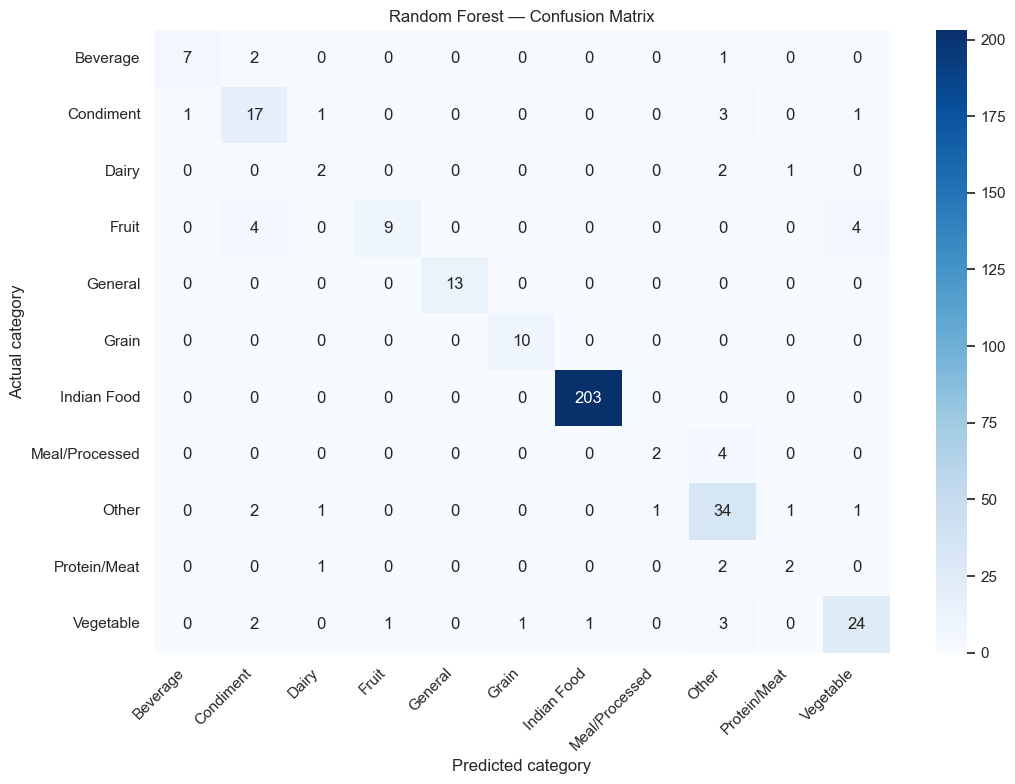

In [25]:
# Random Forest: combines many decision trees and aggregates their predictions.
random_forest_model = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
)
random_forest_model.fit(X_train_scaled, y_train)
rf_metrics = evaluate_classifier(
    "Random Forest", random_forest_model, X_test_scaled, y_test
)

## 8. Part B Model 2 — AdaBoost


AdaBoost — Test-set metrics


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
AdaBoost,0.75,0.676898,0.75,0.700297,0.971009



Classification report:
                precision    recall  f1-score   support

      Beverage       0.00      0.00      0.00        10
     Condiment       0.48      0.65      0.56        23
         Dairy       0.00      0.00      0.00         5
         Fruit       0.00      0.00      0.00        17
       General       0.00      0.00      0.00        13
         Grain       0.00      0.00      0.00        10
   Indian Food       0.99      0.96      0.97       203
Meal/Processed       0.00      0.00      0.00         6
         Other       0.55      0.90      0.69        40
  Protein/Meat       0.00      0.00      0.00         5
     Vegetable       0.38      0.84      0.52        32

      accuracy                           0.75       364
     macro avg       0.22      0.31      0.25       364
  weighted avg       0.68      0.75      0.70       364



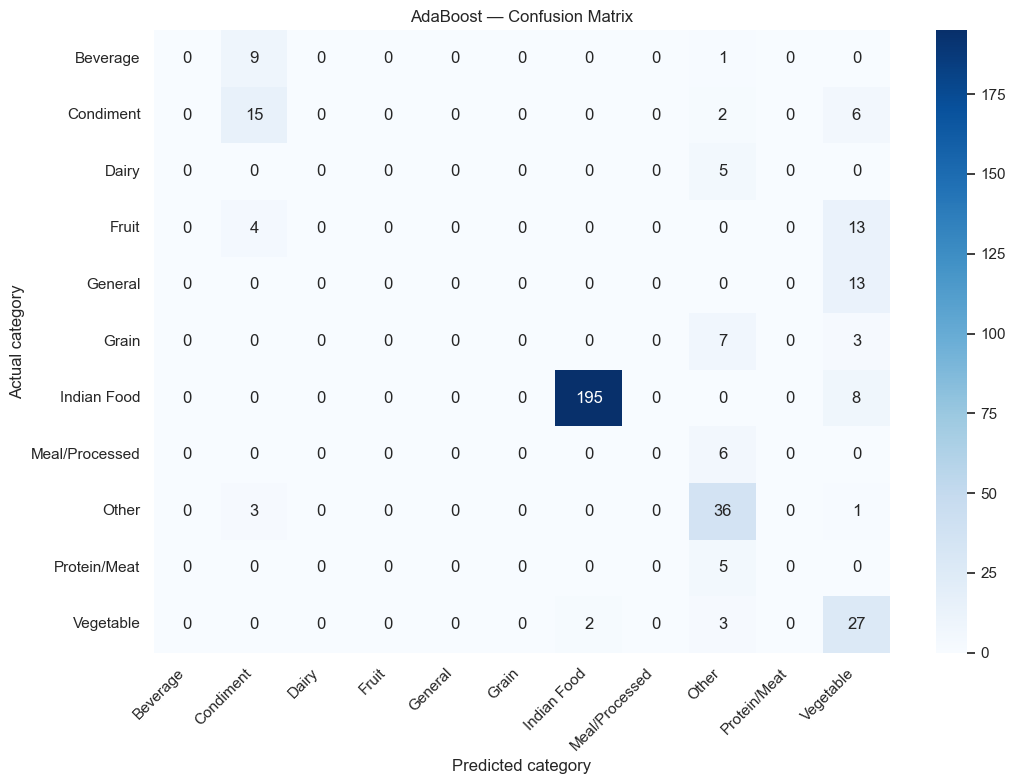

In [26]:
# AdaBoost: sequentially builds weak learners, emphasizing samples that were misclassified.
adaboost_model = AdaBoostClassifier(
    n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
)
adaboost_model.fit(X_train_scaled, y_train)
ada_metrics = evaluate_classifier(
    "AdaBoost", adaboost_model, X_test_scaled, y_test
)

## 9. Part B Model 3 — Gradient Boosting


Gradient Boosting — Test-set metrics


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Gradient Boosting,0.89011,0.888246,0.89011,0.884643,0.99103



Classification report:
                precision    recall  f1-score   support

      Beverage       1.00      0.70      0.82        10
     Condiment       0.65      0.74      0.69        23
         Dairy       0.60      0.60      0.60         5
         Fruit       0.90      0.53      0.67        17
       General       0.93      1.00      0.96        13
         Grain       0.75      0.90      0.82        10
   Indian Food       1.00      1.00      1.00       203
Meal/Processed       0.75      0.50      0.60         6
         Other       0.69      0.82      0.75        40
  Protein/Meat       0.00      0.00      0.00         5
     Vegetable       0.79      0.84      0.82        32

      accuracy                           0.89       364
     macro avg       0.73      0.69      0.70       364
  weighted avg       0.89      0.89      0.88       364



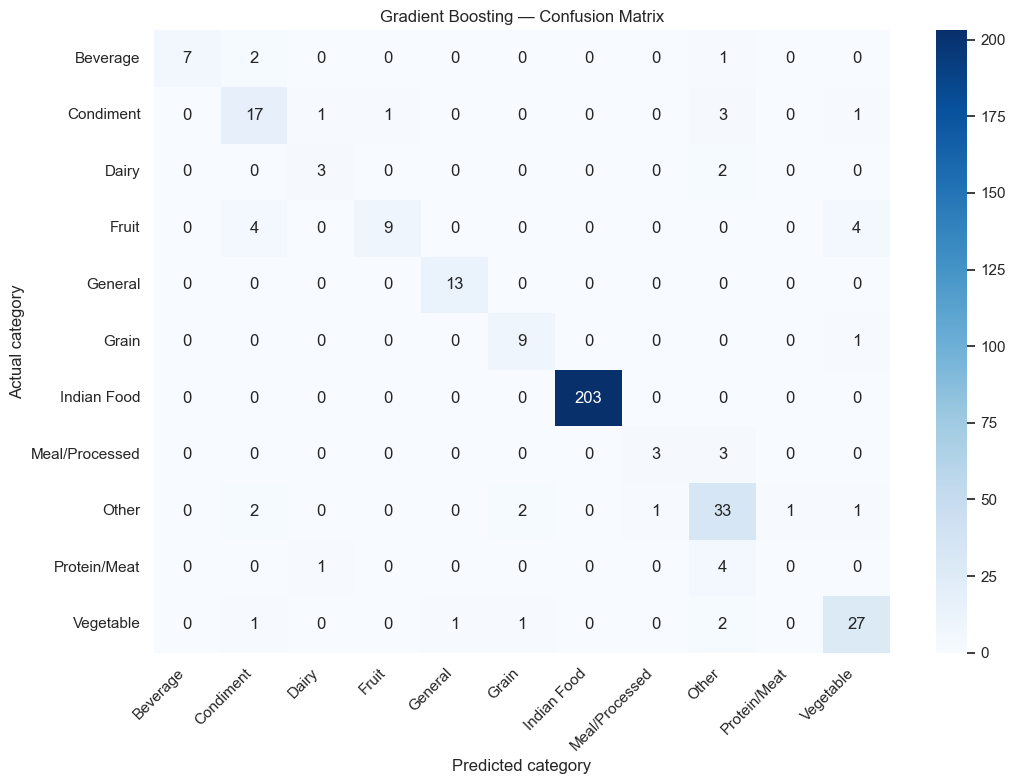

In [27]:
# Gradient Boosting: adds trees sequentially to reduce the remaining classification loss.
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE
)
gradient_boosting_model.fit(X_train_scaled, y_train)
gb_metrics = evaluate_classifier(
    "Gradient Boosting", gradient_boosting_model, X_test_scaled, y_test
)

## 10. Part B Model 4 — Bagging Classifier


Bagging Classifier — Test-set metrics


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Bagging Classifier,0.903846,0.906787,0.903846,0.900314,0.991744



Classification report:
                precision    recall  f1-score   support

      Beverage       0.88      0.70      0.78        10
     Condiment       0.68      0.74      0.71        23
         Dairy       0.57      0.80      0.67         5
         Fruit       1.00      0.65      0.79        17
       General       0.93      1.00      0.96        13
         Grain       0.83      1.00      0.91        10
   Indian Food       1.00      1.00      1.00       203
Meal/Processed       0.50      0.17      0.25         6
         Other       0.70      0.82      0.76        40
  Protein/Meat       0.67      0.40      0.50         5
     Vegetable       0.88      0.88      0.88        32

      accuracy                           0.90       364
     macro avg       0.78      0.74      0.74       364
  weighted avg       0.91      0.90      0.90       364



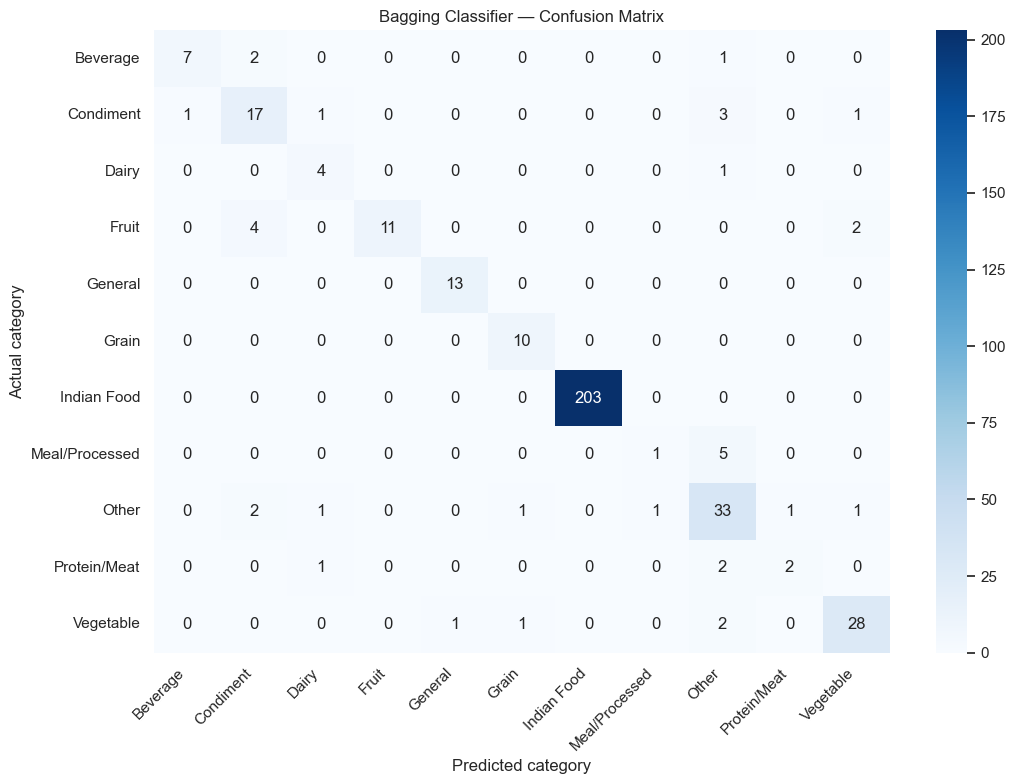

In [28]:
# Bagging: trains multiple decision trees on bootstrapped samples and combines their predictions.
# Supports both recent and older scikit-learn parameter names.
try:
    bagging_model = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    )
except TypeError:
    bagging_model = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    )

bagging_model.fit(X_train_scaled, y_train)
bag_metrics = evaluate_classifier(
    "Bagging Classifier", bagging_model, X_test_scaled, y_test
)

## 11. Part B Model 5 — MLP Classifier


MLP Classifier — Test-set metrics


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
MLP Classifier,0.815934,0.804206,0.815934,0.799848,0.977479



Classification report:
                precision    recall  f1-score   support

      Beverage       0.75      0.30      0.43        10
     Condiment       0.53      0.83      0.64        23
         Dairy       0.00      0.00      0.00         5
         Fruit       0.92      0.65      0.76        17
       General       0.71      0.38      0.50        13
         Grain       0.67      0.60      0.63        10
   Indian Food       0.97      0.99      0.98       203
Meal/Processed       0.00      0.00      0.00         6
         Other       0.55      0.80      0.65        40
  Protein/Meat       0.00      0.00      0.00         5
     Vegetable       0.70      0.66      0.68        32

      accuracy                           0.82       364
     macro avg       0.53      0.47      0.48       364
  weighted avg       0.80      0.82      0.80       364



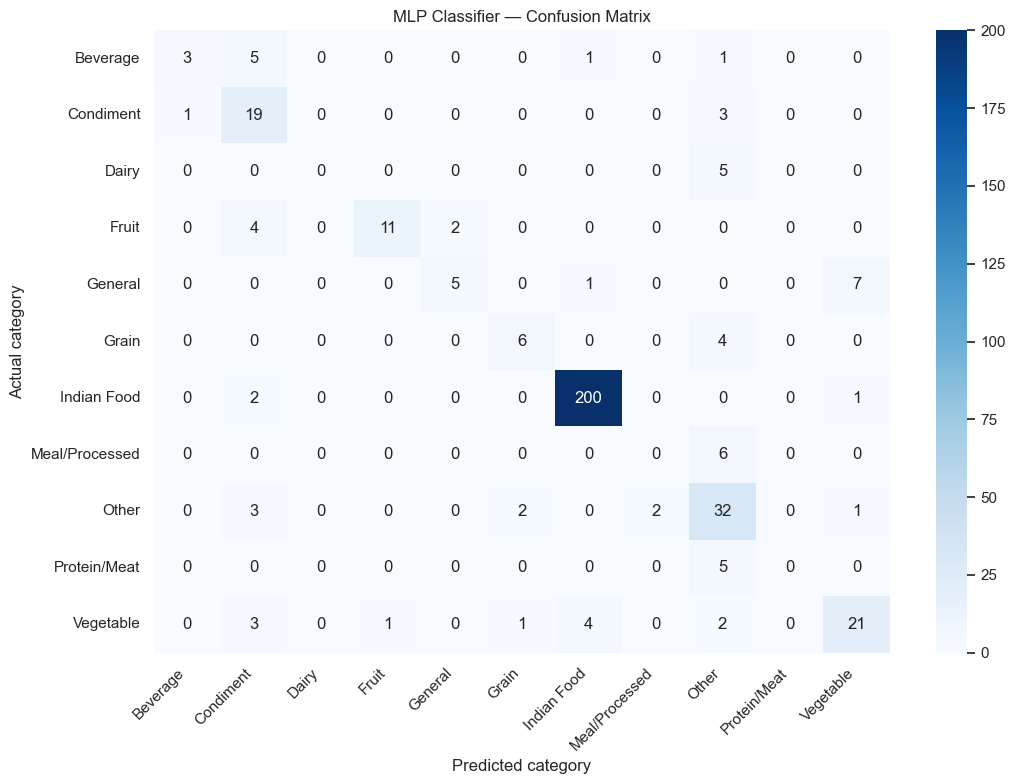

In [29]:
# MLP: a feed-forward neural network; scaling is important for this model.
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=400,
    early_stopping=True,
    random_state=RANDOM_STATE
)
mlp_model.fit(X_train_scaled, y_train)
mlp_metrics = evaluate_classifier(
    "MLP Classifier", mlp_model, X_test_scaled, y_test
)

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
0,Bagging Classifier,0.9038,0.9068,0.9038,0.9003,0.9917
1,Gradient Boosting,0.8901,0.8882,0.8901,0.8846,0.9910
2,Random Forest,0.8874,0.8914,0.8874,0.8846,0.9909
3,MLP Classifier,0.8159,0.8042,0.8159,0.7998,0.9775
4,AdaBoost,0.7500,0.6769,0.7500,0.7003,0.9710


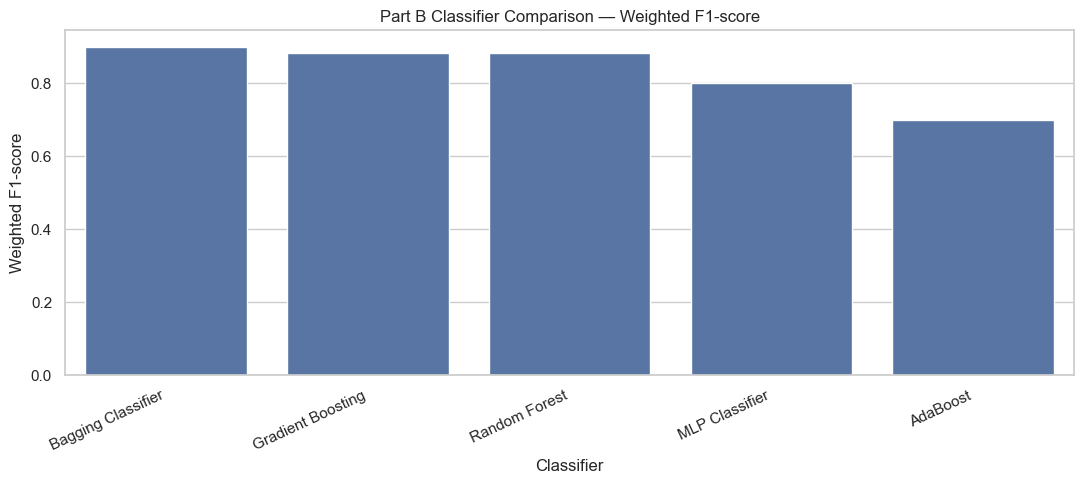

In [30]:
comparison = pd.DataFrame(
    [result["metrics"] for result in part_b_results.values()]
).sort_values("F1-score (weighted)", ascending=False).reset_index(drop=True)

display(comparison.style.format({
    "Accuracy": "{:.4f}",
    "Precision (weighted)": "{:.4f}",
    "Recall (weighted)": "{:.4f}",
    "F1-score (weighted)": "{:.4f}",
    "ROC-AUC (OvR)": "{:.4f}",
}))

plt.figure(figsize=(11, 5))
sns.barplot(data=comparison, x="Algorithm", y="F1-score (weighted)")
plt.title("Part B Classifier Comparison — Weighted F1-score")
plt.ylabel("Weighted F1-score")
plt.xlabel("Classifier")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Best baseline based on weighted F1: Bagging Classifier
Best parameters: {'estimator__max_depth': None, 'max_samples': 1.0, 'n_estimators': 50}
Best mean CV weighted F1: 0.885

Tuned Bagging Classifier — Test-set metrics


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Tuned Bagging Classifier,0.898352,0.899481,0.898352,0.895479,0.991715



Classification report:
                precision    recall  f1-score   support

      Beverage       0.88      0.70      0.78        10
     Condiment       0.69      0.78      0.73        23
         Dairy       0.57      0.80      0.67         5
         Fruit       0.92      0.65      0.76        17
       General       0.93      1.00      0.96        13
         Grain       0.83      1.00      0.91        10
   Indian Food       1.00      1.00      1.00       203
Meal/Processed       0.33      0.17      0.22         6
         Other       0.70      0.80      0.74        40
  Protein/Meat       0.67      0.40      0.50         5
     Vegetable       0.87      0.81      0.84        32

      accuracy                           0.90       364
     macro avg       0.76      0.74      0.74       364
  weighted avg       0.90      0.90      0.90       364



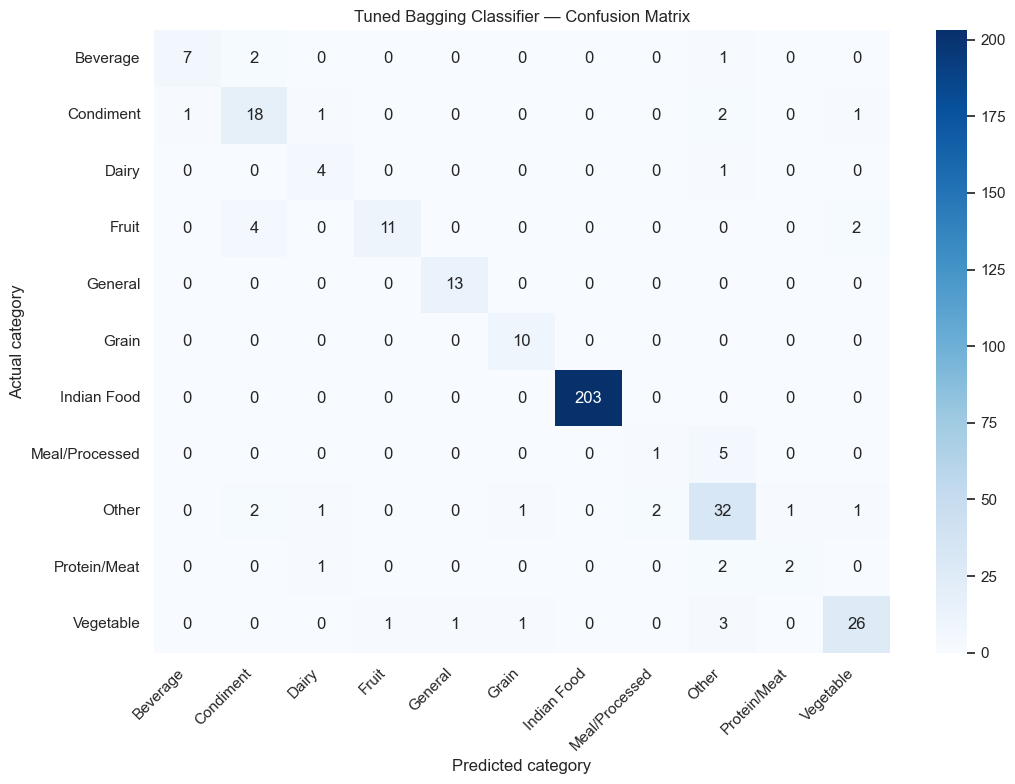

In [32]:
best_baseline_name = comparison.iloc[0]["Algorithm"]
print("Best baseline based on weighted F1:", best_baseline_name)

# Keep the tuning grid focused so it is practical to run on this dataset.
if best_baseline_name == "Random Forest":
    tuning_model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    param_grid = {
        "n_estimators": [100, 200],
        "max_depth": [None, 15],
        "min_samples_leaf": [1, 2],
    }
elif best_baseline_name == "AdaBoost":
    tuning_model = AdaBoostClassifier(random_state=RANDOM_STATE)
    param_grid = {
        "n_estimators": [50, 100],
        "learning_rate": [0.25, 0.5, 1.0],
    }
elif best_baseline_name == "Gradient Boosting":
    tuning_model = GradientBoostingClassifier(random_state=RANDOM_STATE)
    param_grid = {
        "n_estimators": [50, 100],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3],
    }
elif best_baseline_name == "Bagging Classifier":
    try:
        tuning_model = BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            random_state=RANDOM_STATE, n_jobs=-1
        )
        estimator_param = "estimator__max_depth"
    except TypeError:
        tuning_model = BaggingClassifier(
            base_estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            random_state=RANDOM_STATE, n_jobs=-1
        )
        estimator_param = "base_estimator__max_depth"
    param_grid = {
        "n_estimators": [50, 100],
        "max_samples": [0.8, 1.0],
        estimator_param: [None, 10],
    }
else:
    tuning_model = MLPClassifier(
        max_iter=400, early_stopping=True, random_state=RANDOM_STATE
    )
    param_grid = {
        "hidden_layer_sizes": [(64, 32), (100,)],
        "alpha": [0.0001, 0.001],
    }

tuning_search = GridSearchCV(
    tuning_model, param_grid, scoring="f1_weighted",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, refit=True, verbose=0
)
tuning_search.fit(X_train_scaled, y_train)

print("Best parameters:", tuning_search.best_params_)
print("Best mean CV weighted F1:", round(tuning_search.best_score_, 4))

tuned_model = tuning_search.best_estimator_
tuned_metrics = evaluate_classifier(
    f"Tuned {best_baseline_name}", tuned_model, X_test_scaled, y_test
)

## 15. Final Part B summary

In [33]:
final_comparison = pd.concat(
    [
        comparison,
        pd.DataFrame([tuned_metrics])
    ],
    ignore_index=True
).sort_values("F1-score (weighted)", ascending=False).reset_index(drop=True)

display(final_comparison.style.format({
    "Accuracy": "{:.4f}",
    "Precision (weighted)": "{:.4f}",
    "Recall (weighted)": "{:.4f}",
    "F1-score (weighted)": "{:.4f}",
    "ROC-AUC (OvR)": "{:.4f}",
}))

best_final = final_comparison.iloc[0]
print("Best model in this Part B evaluation:", best_final["Algorithm"])
print("Accuracy:", round(best_final["Accuracy"], 4))
print("Weighted F1-score:", round(best_final["F1-score (weighted)"], 4))

# Save the comparison table next to the notebook or in the datasets folder.
output_dir = os.path.dirname(os.path.abspath(DATA_PATH))
comparison_path = os.path.join(output_dir, "nutrition_classification_review2_partB_comparison.csv")
final_comparison.to_csv(comparison_path, index=False)
print("Comparison table saved to:", comparison_path)

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
0,Bagging Classifier,0.9038,0.9068,0.9038,0.9003,0.9917
1,Tuned Bagging Classifier,0.8984,0.8995,0.8984,0.8955,0.9917
2,Gradient Boosting,0.8901,0.8882,0.8901,0.8846,0.9910
3,Random Forest,0.8874,0.8914,0.8874,0.8846,0.9909
4,MLP Classifier,0.8159,0.8042,0.8159,0.7998,0.9775
5,AdaBoost,0.7500,0.6769,0.7500,0.7003,0.9710


Best model in this Part B evaluation: Bagging Classifier
Accuracy: 0.9038
Weighted F1-score: 0.9003
Comparison table saved to: D:\sem5\ML\case_study\23CSE301-ML-Capstone\datasets\nutrition_classification_review2_partB_comparison.csv
